# 03 · Entender la cohorte completa antes de entrenar redes

Estudiamos todas las imágenes de las 26 prendas que han superado los controles. Sus tamaños de clase son diferentes: **no las igualamos mediante un cupo**. Exploramos fotos de train y medimos baselines en validation. No cargamos fotografías ni predicciones de test.

La cohorte corresponde al repertorio elegido y a sus controles de calidad; no es todo el catálogo ni una medida de demanda comercial.

> **Ejecución guardada y revisada · 25/11/2026.** Las siete celdas de código tienen ejecución y no contienen errores guardados. Publicación `20261124T185853-e7045c19`: 51.506 imágenes de train y 11.532 de validation, después del filtro común aplicado en 02 a las tres particiones. La revisión humana de la galería sigue pendiente donde así se indica.

### ¿Qué es el F1?

El **F1 combina dos medidas: precisión y recall**. Las calculamos para cada clase.

Por ejemplo, para la clase «camisa»:

| Medida | Pregunta que responde |
|---|---|
| **Precisión** | De todas las fotos que el modelo llama «camisa», ¿cuántas son realmente camisas? |
| **Recall** | De todas las camisas que había, ¿cuántas ha encontrado el modelo? |

Necesitamos ambas. Un modelo podría reconocer unas pocas camisas con mucha precisión, pero dejarse muchas sin detectar. También podría encontrar casi todas, pero llamar «camisa» a muchas prendas que no lo son.

**El F1 es alto cuando tanto la precisión como el recall son altos.** Va de 0 a 1: cuanto mayor, mejor.

Su fórmula es:

`F1 = 2 × precisión × recall / (precisión + recall)`

### ¿Y qué significa macro-F1?

Calculamos el F1 de cada una de las 26 clases y hacemos la media.

**Todas las clases cuentan lo mismo**, aunque unas tengan muchas más fotos que otras. Así evitamos que las clases abundantes oculten un mal resultado en las menos frecuentes.

In [1]:
from pathlib import Path
import sys,json,time,hashlib
import base64
from html import escape
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown, HTML, Image as DisplayImage
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib','inline')
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/data/local_dataset.py').is_file())
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/'src/data'))
from notebook_utils import setup,styled,save_figure,es,BLUE,ORANGE
from data_contract import sha256, require_current_visual_review
setup()
protocol=json.loads((ROOT/'config/experimental_protocol_v1.json').read_text())
output=ROOT/'data/processed'
pointer=json.loads((output/'CURRENT.json').read_text())
run=output/pointer['run_dir']
checks=json.loads((run/'checksums.json').read_text())
assert sha256(run/'image_manifest.csv.gz')==checks['image_manifest.csv.gz']
manifest=pd.read_csv(run/'image_manifest.csv.gz',dtype={'article_id':'string','product_code':'string','group_id':'string'},keep_default_na=False)
train=manifest.loc[manifest.split.eq('train')].copy()
validation=manifest.loc[manifest.split.eq('validation')].copy()
labels=json.loads((run/'labels.json').read_text())
names=sorted(labels,key=labels.get)
expected_scope=json.loads((ROOT/'config/local_images_v1.json').read_text())
assert set(names)==set(expected_scope['include_classes']), 'Ejecutar 02 con el alcance vigente antes del EDA'
preparation=json.loads((run/'config.json').read_text())
require_current_visual_review(ROOT, run, expected_scope, preparation)
RESULTS=ROOT/'results/metrics/03_eda';RESULTS.mkdir(parents=True,exist_ok=True)
SEED=42
assert set(train.group_id).isdisjoint(validation.group_id)
display(Markdown(f"**Publicación:** `{run.name}` · Train: {es(len(train))} · Validation: {es(len(validation))}."))
display(styled(pd.Series(protocol['default_loss'],name='Pérdida inicial de las futuras redes').to_frame()))

**Publicación:** `20261124T185853-e7045c19` · Train: 51.506 · Validation: 11.532.

Referencia,Pérdida inicial de las futuras redes
name,cross_entropy
class_weights,No


## 2. Cuántas fotos conserva cada clase

La tabla muestra, para cada tipo de prenda:

- Cuántas fotos válidas había al principio.
- Cuántas conservamos después de los controles.
- Qué porcentaje del conjunto final representa esa clase.

**No buscamos que todas las clases tengan el mismo número de fotos.** Conservamos todas las que superan los controles. Por eso puede haber más pantalones que cárdigans.

En validation y test mantenemos juntas las fotos de productos relacionados. Como cada grupo contiene distintas cantidades de fotos, los porcentajes del reparto son aproximados.

Los porcentajes mostrados describen las fotos que hemos conservado. No los ajustamos para representar un conjunto diferente.

In [2]:
selected=manifest.loc[manifest.split.ne('excluded')]
valid_scope=manifest.loc[manifest.image_valid & manifest.label.isin(names)]
counts=pd.DataFrame({'Válidas en origen':valid_scope.label.value_counts(),'Conservadas':selected.label.value_counts()}).loc[names]
counts['Conservadas (%)']=100*counts.Conservadas/counts.Conservadas.sum()
counts['Retenidas de las válidas (%)']=100*counts.Conservadas/counts['Válidas en origen']
display(styled(counts,2))
counts.to_csv(RESULTS/'sampling_distribution.csv')
priors=(counts.Conservadas/counts.Conservadas.sum()).to_dict()
(RESULTS/'eligible_population_priors.json').write_text(json.dumps({'population':'all selected garment types after common quality checks, no caps','priors':priors,'status':'descriptive cohort frequencies, not demand or entire catalog'},indent=2))
weights=json.loads((run/'training_class_weights.json').read_text())
display(Markdown(f"Pesos opcionales de la pérdida: **{es(min(weights.values()),3)} a {es(max(weights.values()),3)}**. Con frecuencias desiguales pueden alejarse de uno; la referencia sigue sin pesos y H4 medirá su efecto."))

Clase,Válidas en origen,Conservadas,Conservadas (%),Retenidas de las válidas (%)
Blazer,1.108,1.073,"1,45","96,84"
Blouse,3.975,3.917,"5,28","98,54"
Bodysuit,911,899,"1,21","98,68"
Cardigan,1.546,1.526,"2,06","98,71"
Coat,460,453,"0,61","98,48"
Costumes,89,65,"0,09","73,03"
Dress,10.348,10.257,"13,84","99,12"
Dungarees,309,289,"0,39","93,53"
Garment Set,1.319,1.291,"1,74","97,88"
Hoodie,2.356,2.269,"3,06","96,31"


Pesos opcionales de la pérdida: **0,265 a 47,167**. Con frecuencias desiguales pueden alejarse de uno; la referencia sigue sin pesos y H4 medirá su efecto.

### 3. ¿Para qué sirve esta galería?

Mostramos hasta ocho productos distintos de cada clase para ver cómo son las fotos con las que trabajaremos.

Revisamos si se reconoce la prenda, cómo es el fondo y si la etiqueta parece correcta. CLIP ya ha filtrado imágenes en el 02, pero puede equivocarse; esta es una revisión humana adicional.

**Solo mostramos unas pocas fotos: las demás siguen disponibles para entrenar.** Utilizamos fotos de train para mantener test reservado para la evaluación final.

Si una anotación dice «pendiente», significa que todavía no la hemos rellenado.


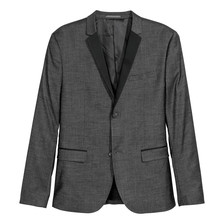
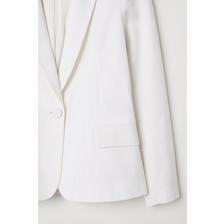
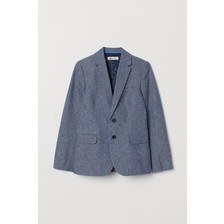
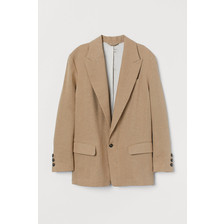
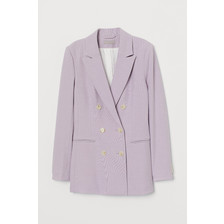
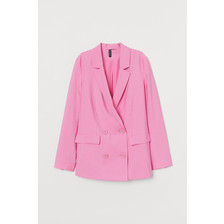
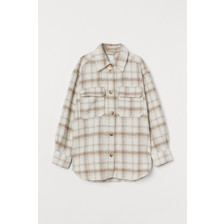
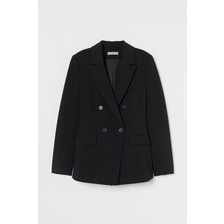
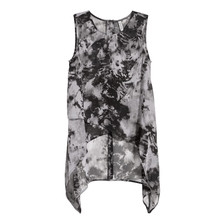
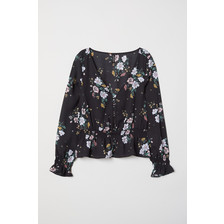
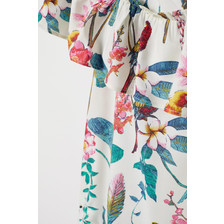
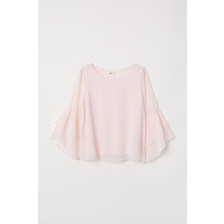
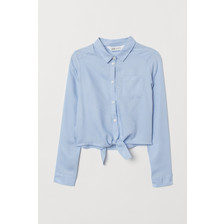
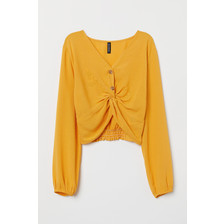
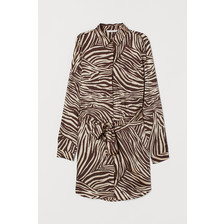
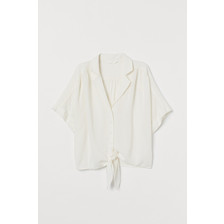
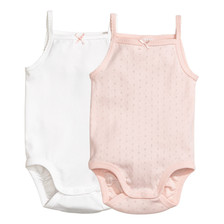
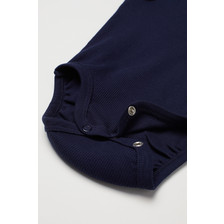
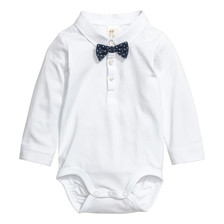
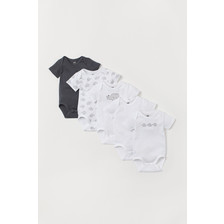
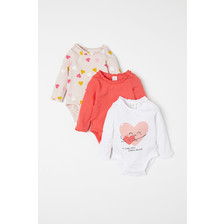
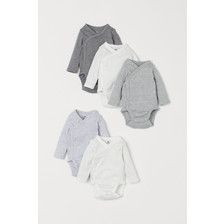
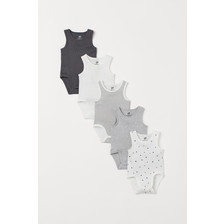
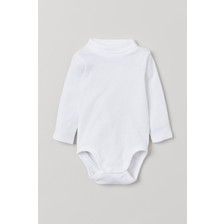


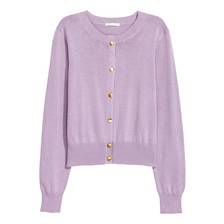
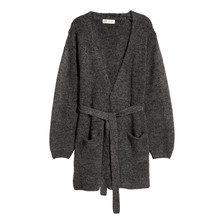
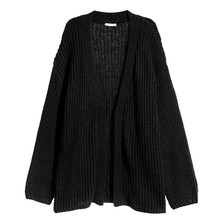
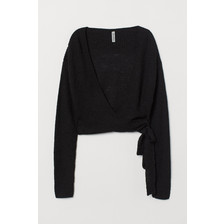
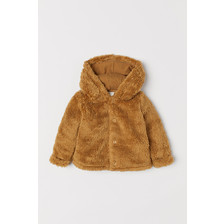
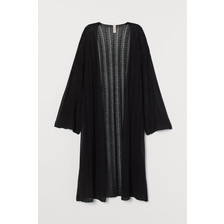
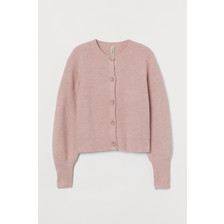
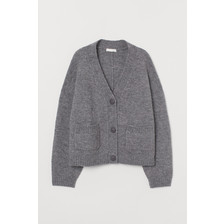
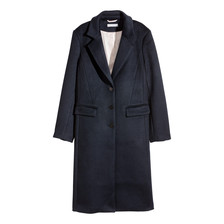
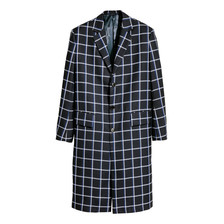
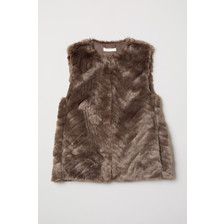
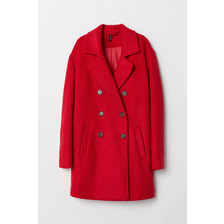
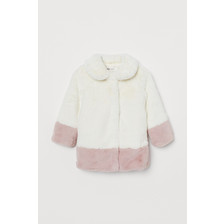
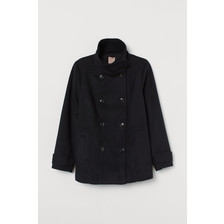
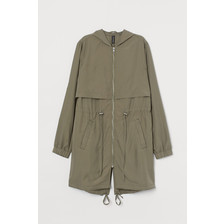
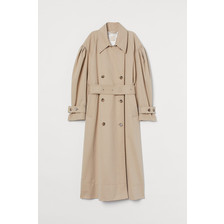
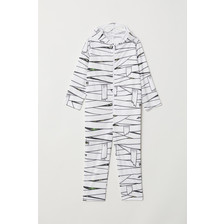
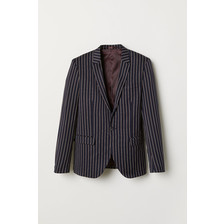
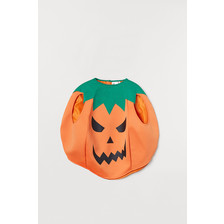
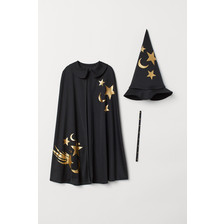
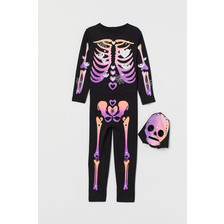
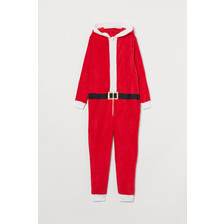
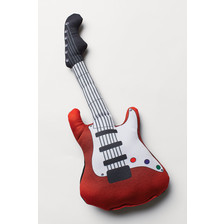
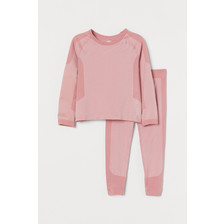


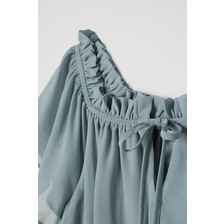
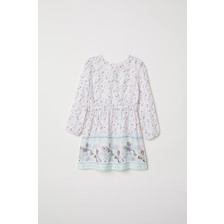
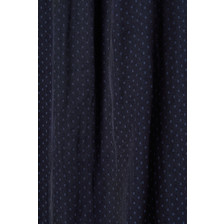
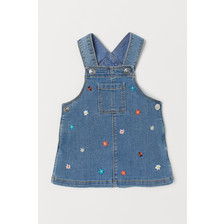
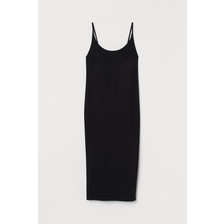
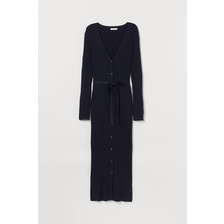
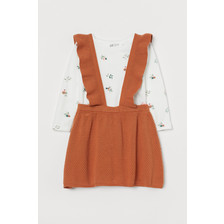
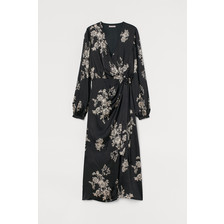
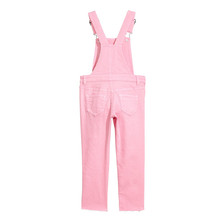
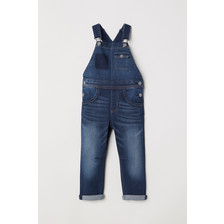
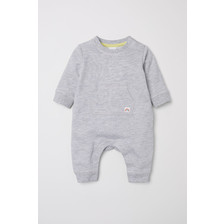
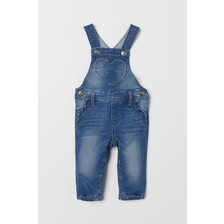
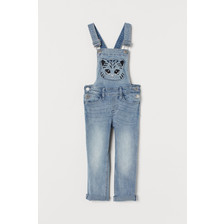
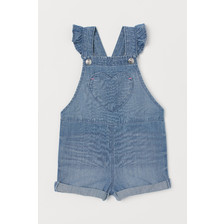
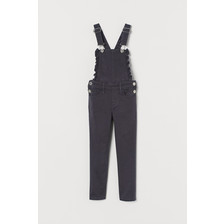
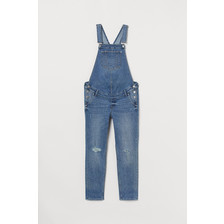
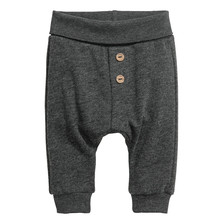
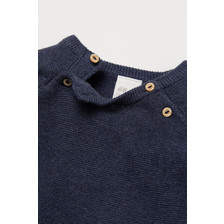
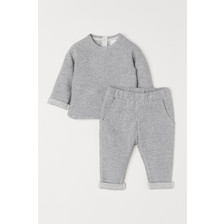
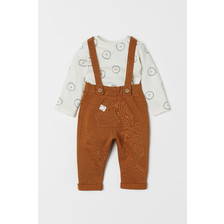
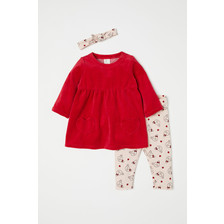
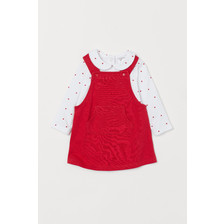
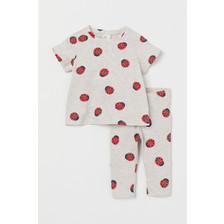
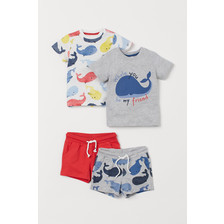


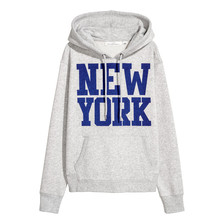
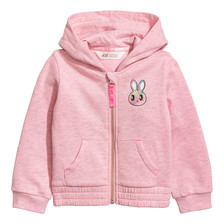
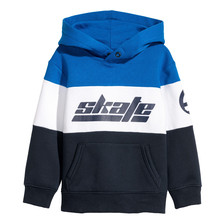
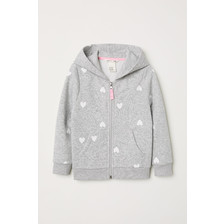
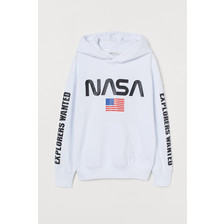
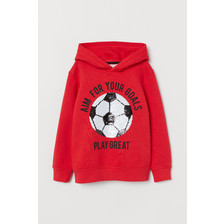
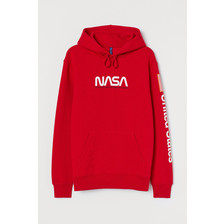
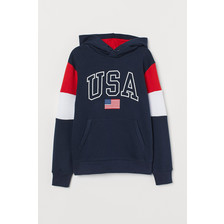
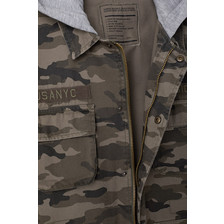
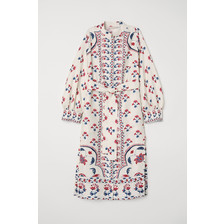
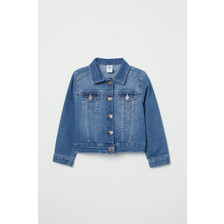
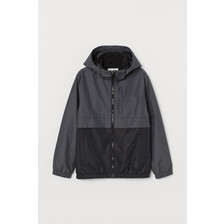
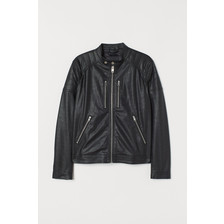
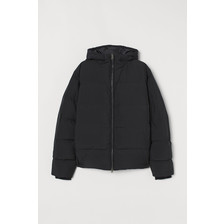
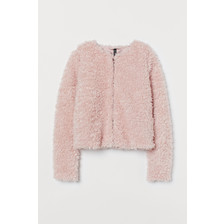
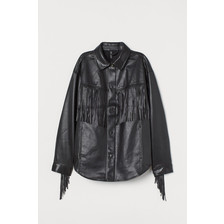
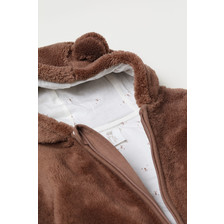
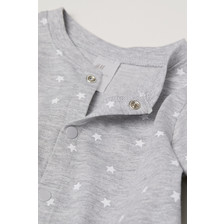
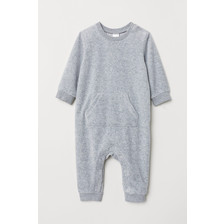
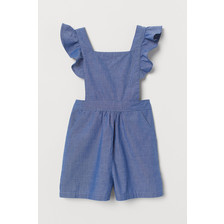
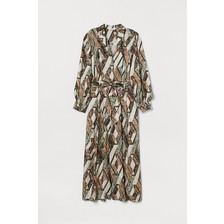
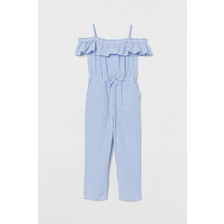
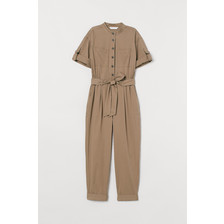
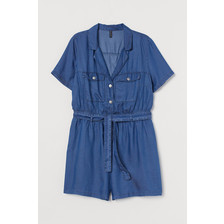


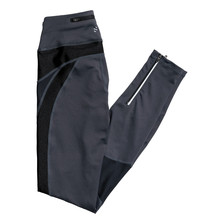
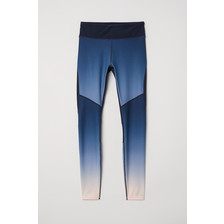
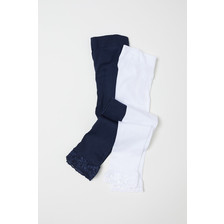
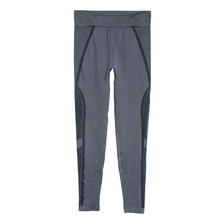
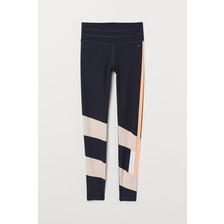
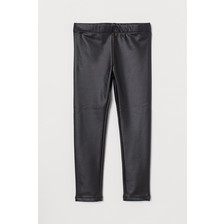
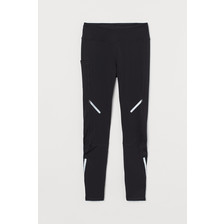
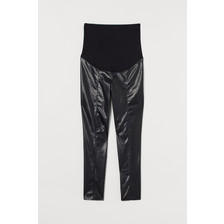
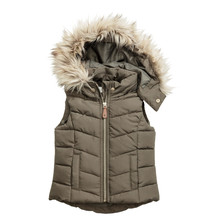
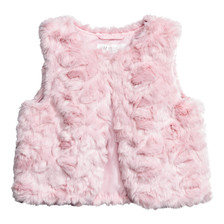
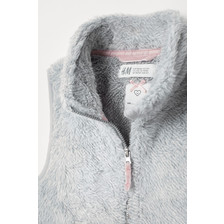
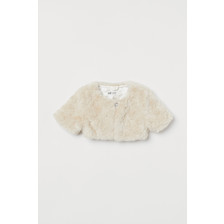
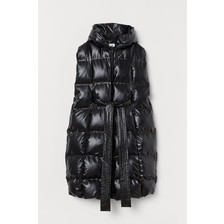
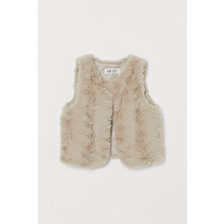
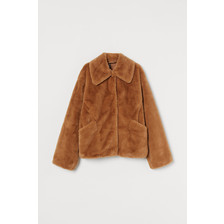
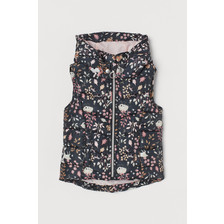
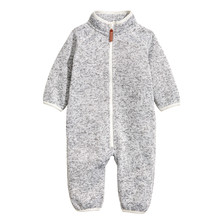
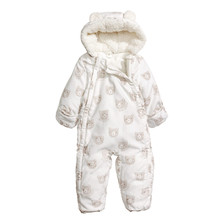
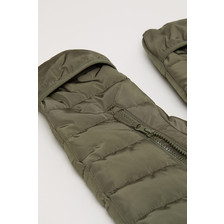
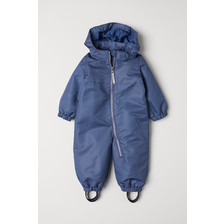
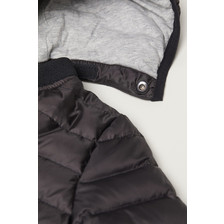
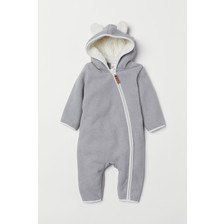
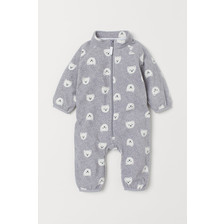
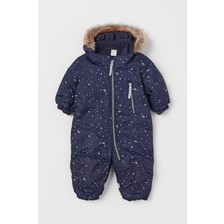


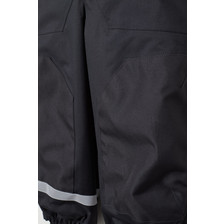
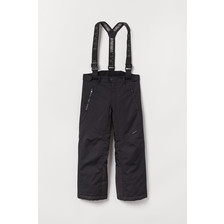
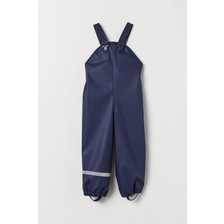
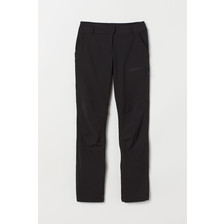
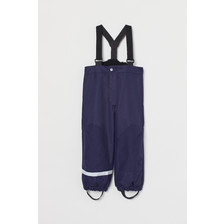
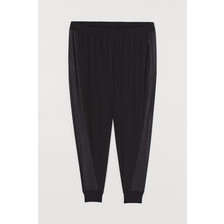
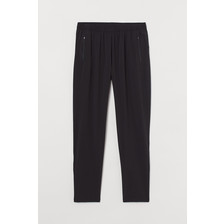
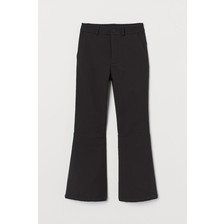
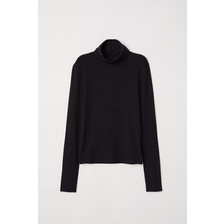
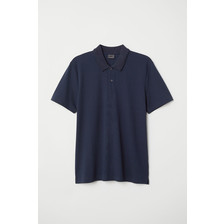
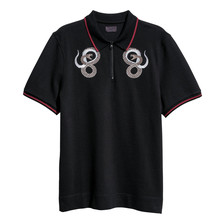
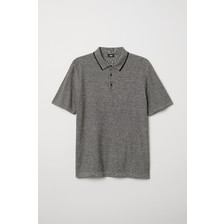
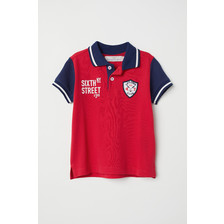
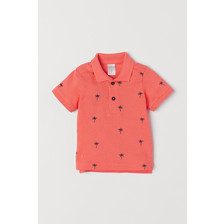
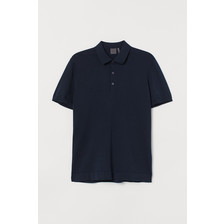
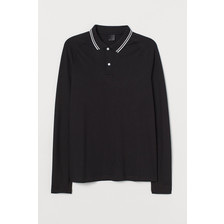
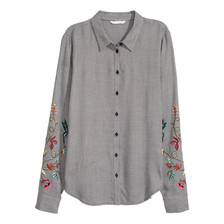
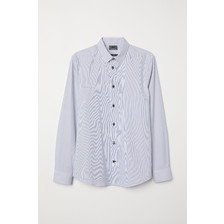
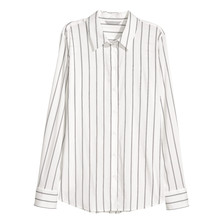
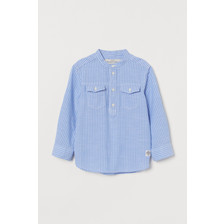
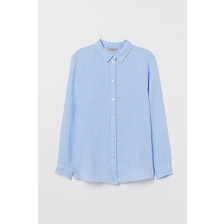
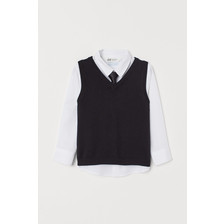
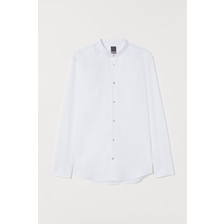
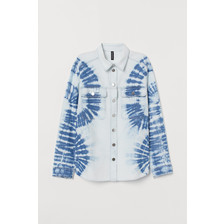


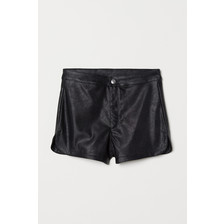
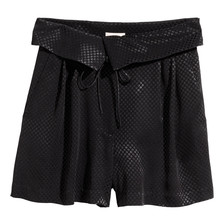
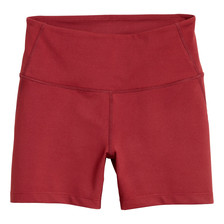
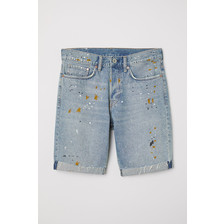
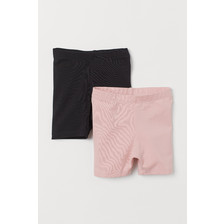
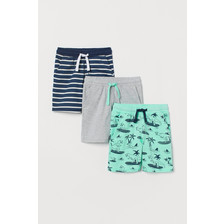
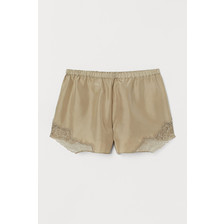
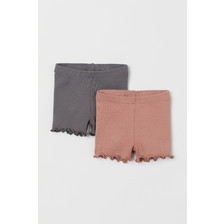
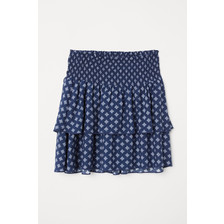
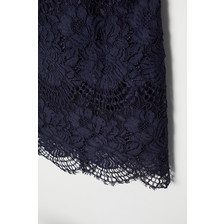
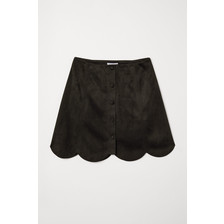
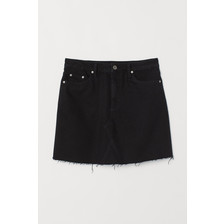
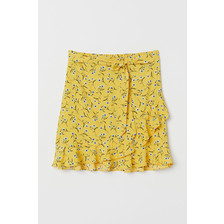
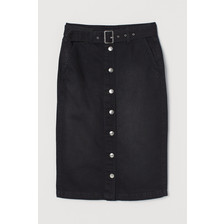
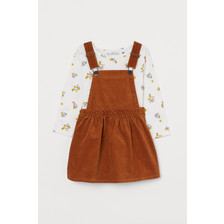
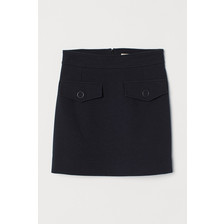
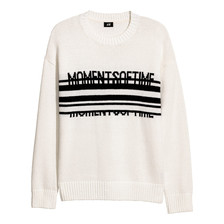
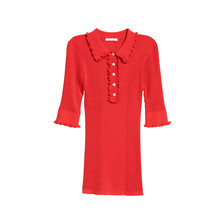
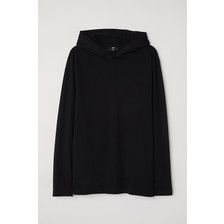
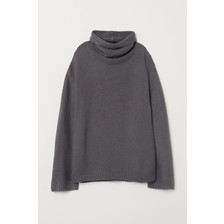
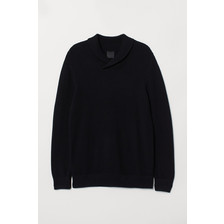
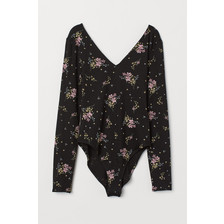
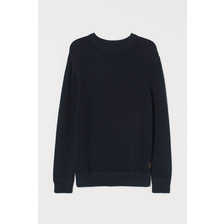
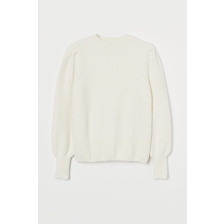


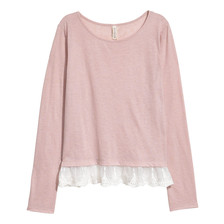
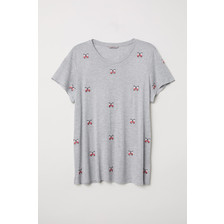
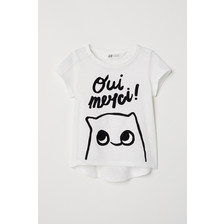
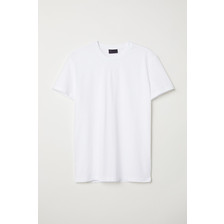
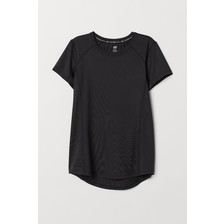
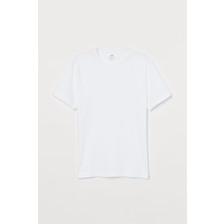
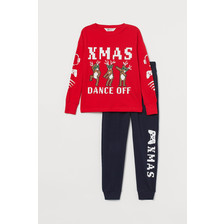
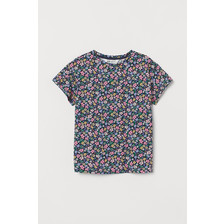
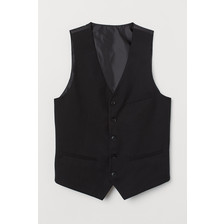
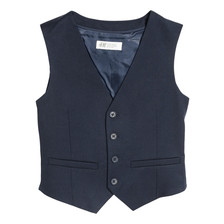
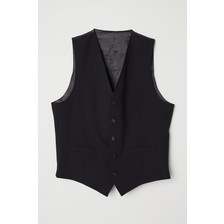
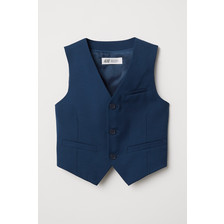
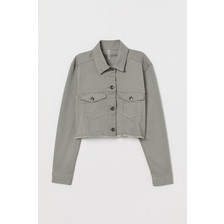
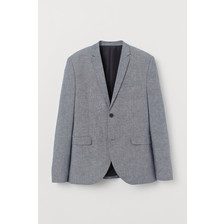
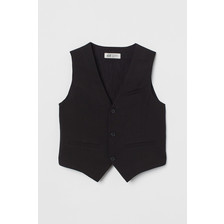
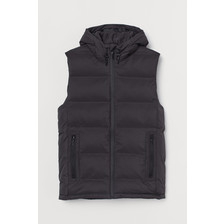
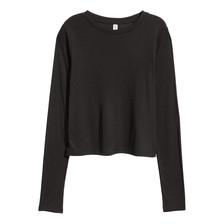
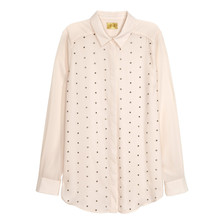
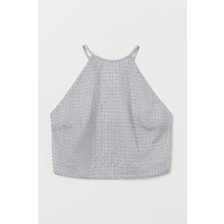
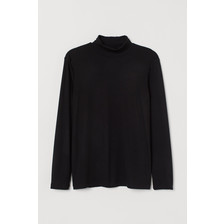
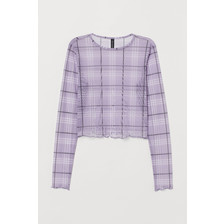
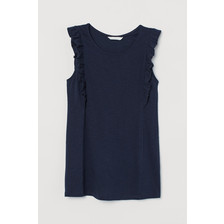
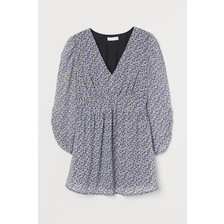
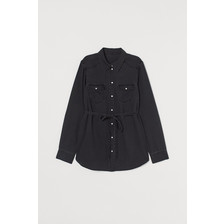


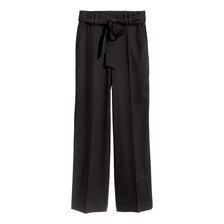
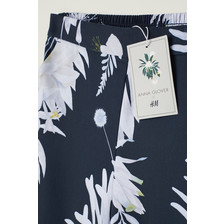
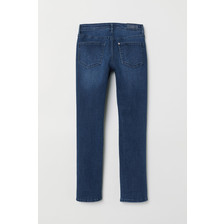
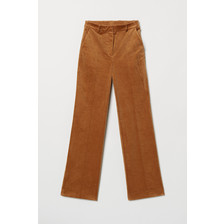
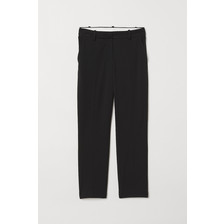
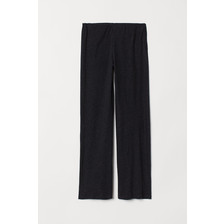
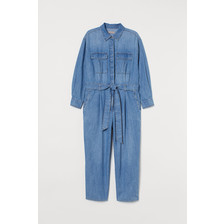
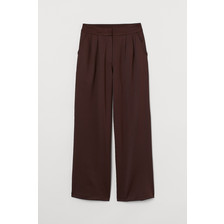
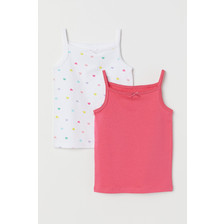
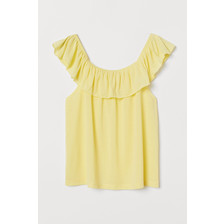
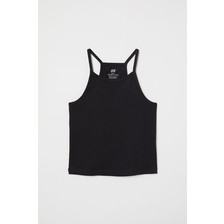
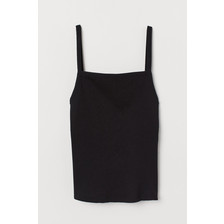
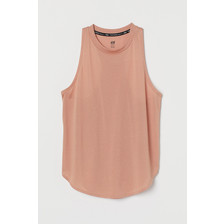
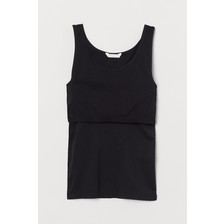
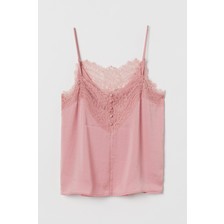
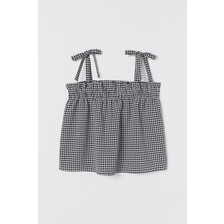

**Muestra de revisión:** 208 productos. **Plantilla:** `results\metrics\03_eda\training_visual_review_648d4a779f1b.csv`. Las anotaciones pendientes no se presentan como observaciones confirmadas.

In [3]:
review=[]
review_per_class=int(protocol['class_review']['training_review_products_per_class'])
for label,part in train.groupby('label',sort=True):
    representatives=part.sort_values('article_id').drop_duplicates('group_id')
    review.append(representatives.sample(n=min(review_per_class,len(representatives)),random_state=SEED))
review=pd.concat(review).sort_values(['label','article_id'])
assert len(review)==review.group_id.nunique()
assert review.groupby('label').size().le(review_per_class).all()
review_key=sha256(run/'image_manifest.csv.gz')[:12]
review_path=RESULTS/f'training_visual_review_{review_key}.csv'
columns=['article_id','product_code','group_id','label','image_path']
if not review_path.exists():
    annotation=review[columns].copy()
    for field in ['background_type','pose_or_presentation','label_consistency','uncertainty','notes']:
        annotation[field]='pending'
    annotation.to_csv(review_path,index=False)
else:
    existing=pd.read_csv(review_path,dtype={'article_id':'string'})
    assert set(existing.article_id)==set(review.article_id),'No sobrescribir revisión de otra muestra'
# Imports locales: esta presentación no depende de recargar el entorno inicial.
import base64
from html import escape
from IPython.display import HTML

page_size=24
for page in range((len(review)+page_size-1)//page_size):
    part=review.iloc[page*page_size:(page+1)*page_size]
    cards=[]
    for row in part.itertuples():
        encoded=base64.b64encode((output/row.image_path).read_bytes()).decode('ascii')
        caption=f'{escape(str(row.label))}<br><span style="color:#667085">{escape(str(row.article_id))}</span>'
        cards.append(
            '<figure style="margin:0;width:116px;text-align:center">'
            f'<img src="data:image/jpeg;base64,{encoded}" '
            'style="width:104px;height:136px;object-fit:contain;background:white" '
            f'alt="{escape(str(row.label))} · {escape(str(row.article_id))}">'
            f'<figcaption style="font-size:12px;line-height:1.3;margin-top:5px;overflow-wrap:anywhere">{caption}</figcaption></figure>'
        )
    expanded=' open' if page==0 else ''
    display(HTML(
        f'<details{expanded} style="max-width:800px;margin:10px 0 18px;'
        'border:1px solid #DDE3EA;border-top:3px solid #F18D01;padding:10px;background:white;color:#17212B">'
        f'<summary style="cursor:pointer;color:#00458A;font-weight:600">Revisión de train · Bloque {page+1} · {len(part)} fotos</summary>'
        '<div style="display:flex;flex-wrap:wrap;gap:14px 12px;margin-top:12px">'
        +''.join(cards)+'</div></details>'
    ))
display(Markdown(f'**Muestra de revisión:** {es(len(review))} productos. **Plantilla:** `{review_path.relative_to(ROOT)}`. Las anotaciones pendientes no se presentan como observaciones confirmadas.'))

## 4. Segmentos comerciales: prendas infantiles y adultas

`index_group_name` es una categoría comercial suministrada por H&M. Su distribución por clase permite detectar si la comparación mezcla líneas de producto diferentes. No atribuimos una pose, edad o calidad visual a una imagen a partir de esa columna.

In [4]:
segments=pd.crosstab(train.label,train.index_group_name).reindex(names)
display(styled(segments))
display(styled(100*segments.div(segments.sum(axis=1),axis=0),1))
segments.to_csv(RESULTS/'training_commercial_segments.csv')

Clase,Baby/Children,Divided,Ladieswear,Menswear,Sport
Blazer,53,65,439,179,0
Blouse,298,497,1.872,0,0
Bodysuit,486,24,135,0,0
Cardigan,429,224,319,103,0
Coat,8,43,177,73,0
Costumes,42,0,0,1,0
Dress,1.699,1.695,3.782,0,0
Dungarees,123,68,7,0,0
Garment Set,901,0,7,0,23
Hoodie,674,241,102,384,152


Clase,Baby/Children,Divided,Ladieswear,Menswear,Sport
Blazer,"7,2","8,8","59,6","24,3",0
Blouse,"11,2","18,6","70,2",0,0
Bodysuit,"75,3","3,7","20,9",0,0
Cardigan,"39,9","20,8","29,7","9,6",0
Coat,"2,7","14,3","58,8","24,3",0
Costumes,"97,7",0,0,"2,3",0
Dress,"23,7","23,6","52,7",0,0
Dungarees,"62,1","34,3","3,5",0,0
Garment Set,"96,8",0,"0,8",0,"2,5"
Hoodie,"43,4","15,5","6,6","24,7","9,8"


## 5. Describir los colores y el brillo de las fotos

Convertimos cada fotografía en unos pocos números para estudiar cómo varían las imágenes de una misma clase.

| Qué medimos | Qué nos cuenta |
|---|---|
| Cantidad de cada intervalo de color | Cuánto aparecen distintos niveles de rojo, verde y azul |
| Brillo medio | Si la imagen es, en conjunto, clara u oscura |
| Variación de intensidad | Cuánto contraste hay entre sus zonas claras y oscuras |
| Brillo de las esquinas | Cómo son las esquinas de la imagen |

Para resumir los colores, dividimos cada canal —rojo, verde y azul— en 16 intervalos. Obtenemos así **48 números por foto**. Este resumen cuenta los colores, pero no reconoce mangas, cuellos ni otras partes de la prenda.

Antes de medir, retiramos aproximadamente los bordes blancos añadidos durante la preparación. Aun así, **las esquinas pueden contener parte de la ropa**: su brillo no es una medida exacta del fondo.

Estudiamos estos valores en train para conocer las diferencias entre las fotografías. Por sí solos no permiten saber qué prendas confundirá una CNN ni identificar automáticamente las poses.

La primera lectura puede tardar. Guardamos los números calculados para reutilizarlos mientras no cambien los datos o la forma de calcularlos.

In [5]:
import hashlib
import time
from data_contract import sha256

feature_version='rgbhist16-content-proxies-v1'
fingerprint=hashlib.sha256((sha256(run/'image_manifest.csv.gz')+feature_version).encode()).hexdigest()[:16]
cache=RESULTS/f'features_{fingerprint}.npz'
rows=pd.concat([train,validation],ignore_index=True)
start=time.perf_counter()
if cache.exists():
    data=np.load(cache)
    assert data['article_ids'].tolist()==rows.article_id.tolist()
    X=data['X'];descriptors=data['descriptors']
else:
    features=[];stats=[]
    for i,row in enumerate(rows.itertuples(),1):
        with Image.open(output/row.image_path) as source:
            image=source.convert('RGB');size=image.width
            scale=size/max(row.width,row.height)
            w=max(1,round(row.width*scale));h=max(1,round(row.height*scale))
            left=(size-w)//2;top=(size-h)//2
            content=np.asarray(image.crop((left,top,left+w,top+h)).resize((32,32)),dtype=np.float32)/255
        features.append(np.concatenate([np.histogram(content[:,:,c],bins=16,range=(0,1))[0]/1024 for c in range(3)]))
        corners=np.concatenate([content[:4,:4].ravel(),content[:4,-4:].ravel(),content[-4:,:4].ravel(),content[-4:,-4:].ravel()])
        stats.append([content.mean(),content.std(),corners.mean()])
    X=np.asarray(features,dtype=np.float32);descriptors=np.asarray(stats,dtype=np.float32)
    np.savez_compressed(cache,X=X,descriptors=descriptors,article_ids=rows.article_id.to_numpy(dtype=str))
train_X=X[:len(train)];val_X=X[len(train):]
train_y=train.label_id.astype(int).to_numpy();val_y=validation.label_id.astype(int).to_numpy()
profile=pd.DataFrame(descriptors[:len(train)],columns=['brillo','variacion_intensidad','esquinas_contenido'])
profile['label']=train.label.to_numpy()
display(styled(profile.groupby('label').agg(['median','std']),3))
print('Extracción/carga completada. Forma de características:',X.shape)

Extracción/carga completada. Forma de características: (63038, 48)


## 6. Baselines fijados: mayoría y regresión logística de color

El escalado se ajusta solo con train. La regresión logística usa C=1 y un máximo de 500 iteraciones, sin pesos de clase ni búsqueda de hiperparámetros. Si no converge se informa: no se presenta silenciosamente como un ajuste satisfactorio. La medición de tiempo excluye extracción de características y no representa el coste total de una red. Estos baselines no tienen entrenamiento GPU.

Los intervalos de validation remuestrean grupos de producto completos, manteniendo juntas sus variantes. Son intervalos del conjunto y ajuste actuales, no variabilidad entre entrenamientos ni una prueba de superioridad. Validation sigue disponible para desarrollo; estos números no son resultados finales de test.

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,f1_score,classification_report,confusion_matrix
from threadpoolctl import threadpool_limits
models={'Mayoría train':DummyClassifier(strategy='most_frequent'),
        'Logística de color':make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=500,class_weight=None,random_state=SEED))}
results=[];predictions={};per_class={}
def group_intervals(y,pred,groups,draws=300):
    unique,inverse=np.unique(groups,return_inverse=True)
    cubes=np.zeros((len(unique),len(names),len(names)),dtype=int)
    np.add.at(cubes,(inverse,y,pred),1)
    rng=np.random.default_rng(SEED);samples=[]
    for _ in range(draws):
        cm=cubes[rng.integers(len(unique),size=len(unique))].sum(axis=0)
        tp=cm.diagonal();den=cm.sum(0)+cm.sum(1)
        samples.append([tp.sum()/cm.sum(),np.divide(2*tp,den,out=np.zeros(len(names),dtype=float),where=den>0).mean()])
    return np.quantile(samples,[.025,.975],axis=0)
with threadpool_limits(limits=2):
    for name,model in models.items():
        start=time.perf_counter();model.fit(train_X,train_y);fit_seconds=time.perf_counter()-start
        start=time.perf_counter();pred=model.predict(val_X);predict_seconds=time.perf_counter()-start
        predictions[name]=pred
        ci=group_intervals(val_y,pred,validation.group_id.to_numpy())
        results.append({'Modelo':name,'accuracy':accuracy_score(val_y,pred),'macro_F1':f1_score(val_y,pred,labels=np.arange(len(names)),average='macro',zero_division=0),
                        'accuracy_IC95_inf':ci[0,0],'accuracy_IC95_sup':ci[1,0],'F1_IC95_inf':ci[0,1],'F1_IC95_sup':ci[1,1],
                        'ajuste_s':fit_seconds,'prediccion_ms_imagen':1000*predict_seconds/len(val_y)})
        per_class[name]=classification_report(val_y,pred,labels=np.arange(len(names)),target_names=names,zero_division=0,output_dict=True)
metrics=pd.DataFrame(results).set_index('Modelo');display(styled(metrics,4))
metrics.to_csv(RESULTS/'validation_baselines.csv')
report=pd.DataFrame(per_class['Logística de color']).T;display(styled(report.loc[names],3))
report.to_csv(RESULTS/'validation_colour_per_class.csv')
logistic=models['Logística de color'].named_steps['logisticregression']
converged=bool(logistic.n_iter_.max()<logistic.max_iter)
display(Markdown(f"**Azar uniforme esperado:** {es(100/len(names),2)} % de accuracy; referencia teórica. **Logística dentro del límite de iteraciones:** {converged}."))
np.savez_compressed(RESULTS/'validation_predictions.npz',article_ids=validation.article_id.to_numpy(dtype=str),y=val_y,**{f'model_{i}':pred for i,pred in enumerate(predictions.values())})
# Permite comprobar en 04 que el baseline se ajustó con la misma publicación.
(RESULTS/'dataset_provenance.json').write_text(json.dumps({
    'dataset_run': run.name,
    'manifest_sha256': sha256(run/'image_manifest.csv.gz'),
    'train_images': len(train),
    'validation_images': len(validation),
}, indent=2), encoding='utf-8')

Modelo,Accuracy,Macro-F1,Accuracy · IC95 inferior,Accuracy · IC95 superior,F1 · IC95 inferior,F1 · IC95 superior,Ajuste (s),Predicción (ms/imagen)
Mayoría train,"0,1537","0,0103","0,1384","0,1676","0,0094","0,0110","0,0205","1,48e-05"
Logística de color,"0,2150","0,0455","0,2026","0,2261","0,0430","0,0477","6,9698","0,0005"


Referencia,Precisión,Recall,F1,Imágenes
Blazer,0,0,0,168
Blouse,"0,146","0,010","0,018",620
Bodysuit,0,0,0,138
Cardigan,0,0,0,234
Coat,0,0,0,65
Costumes,0,0,0,7
Dress,"0,181","0,325","0,233",1.559
Dungarees,0,0,0,48
Garment Set,0,0,0,176
Hoodie,0,0,0,346


**Azar uniforme esperado:** 3,85 % de accuracy; referencia teórica. **Logística dentro del límite de iteraciones:** True.

191

## 7. Confusión de un baseline: evidencia limitada a su representación

Una confusión de histogramas de color no demuestra una ambigüedad intrínseca entre prendas: el baseline ignora su disposición espacial. Se publican recuentos y proporciones por clase, para distinguir un fallo sistemático de un efecto del soporte. Las parejas Shirt/T-shirt y Sweater/Cardigan son hipótesis a contrastar, no las seleccionamos a posteriori como si se hubieran predicho a partir de estos resultados.

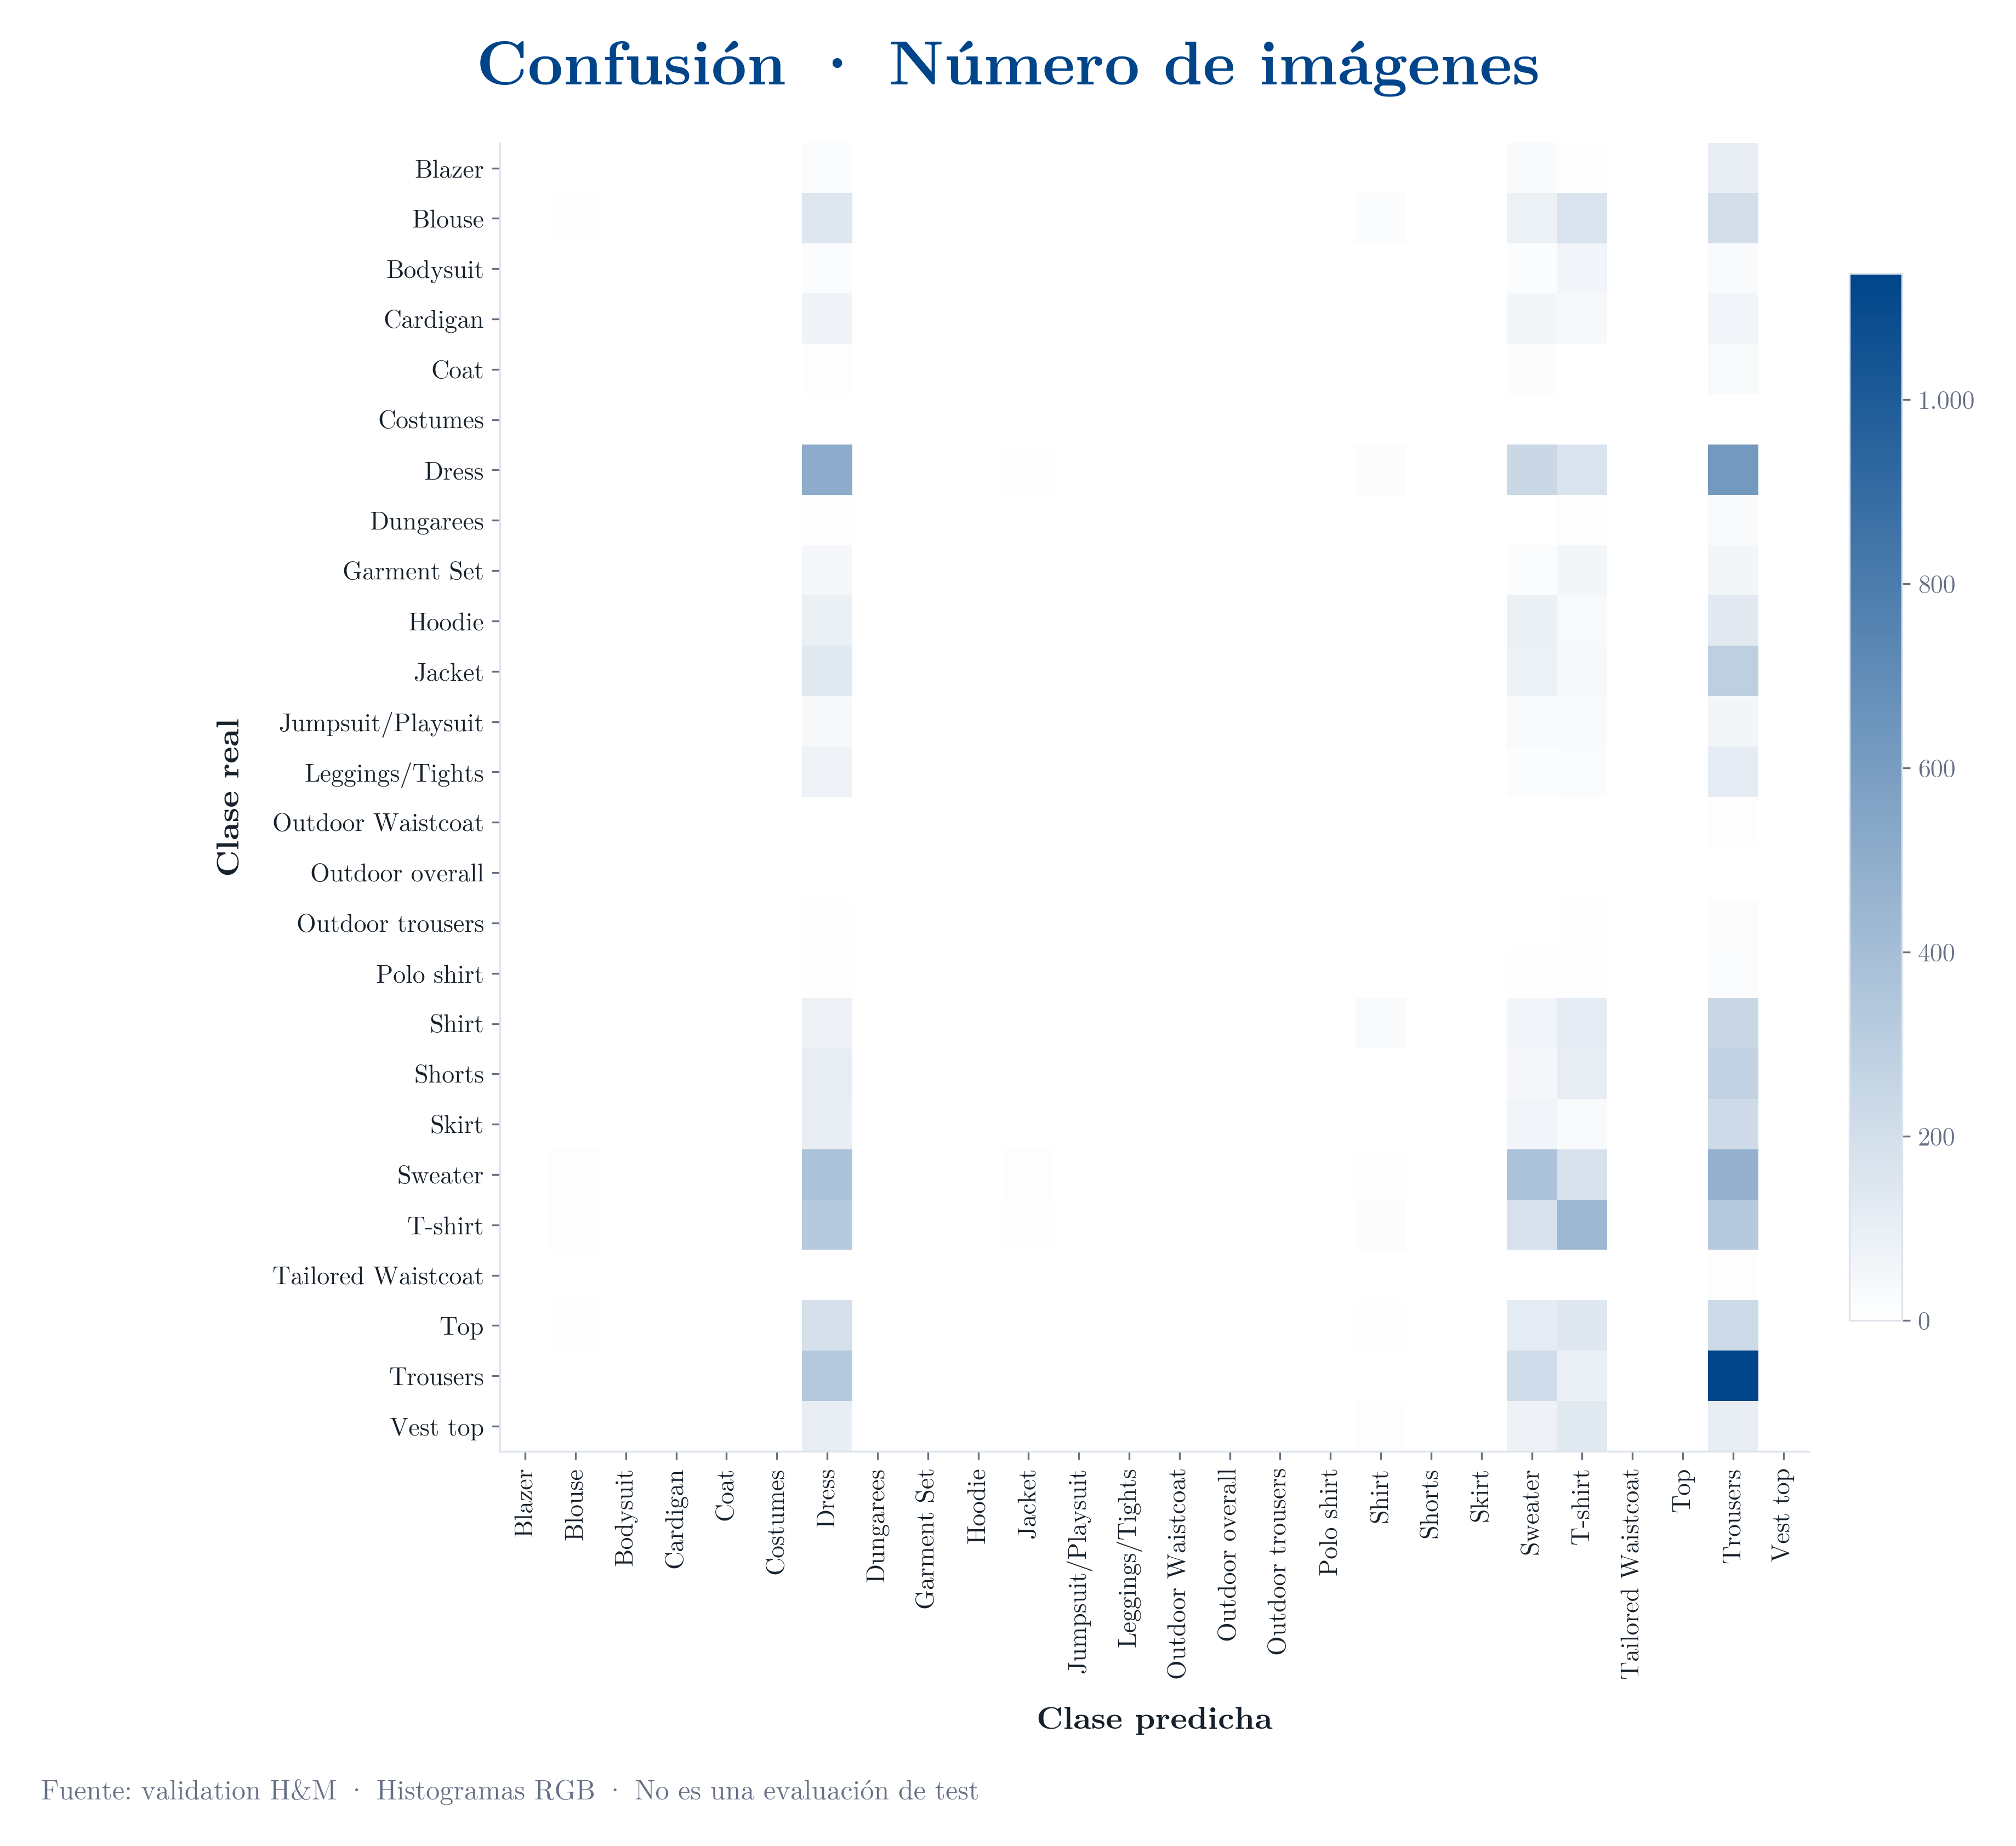

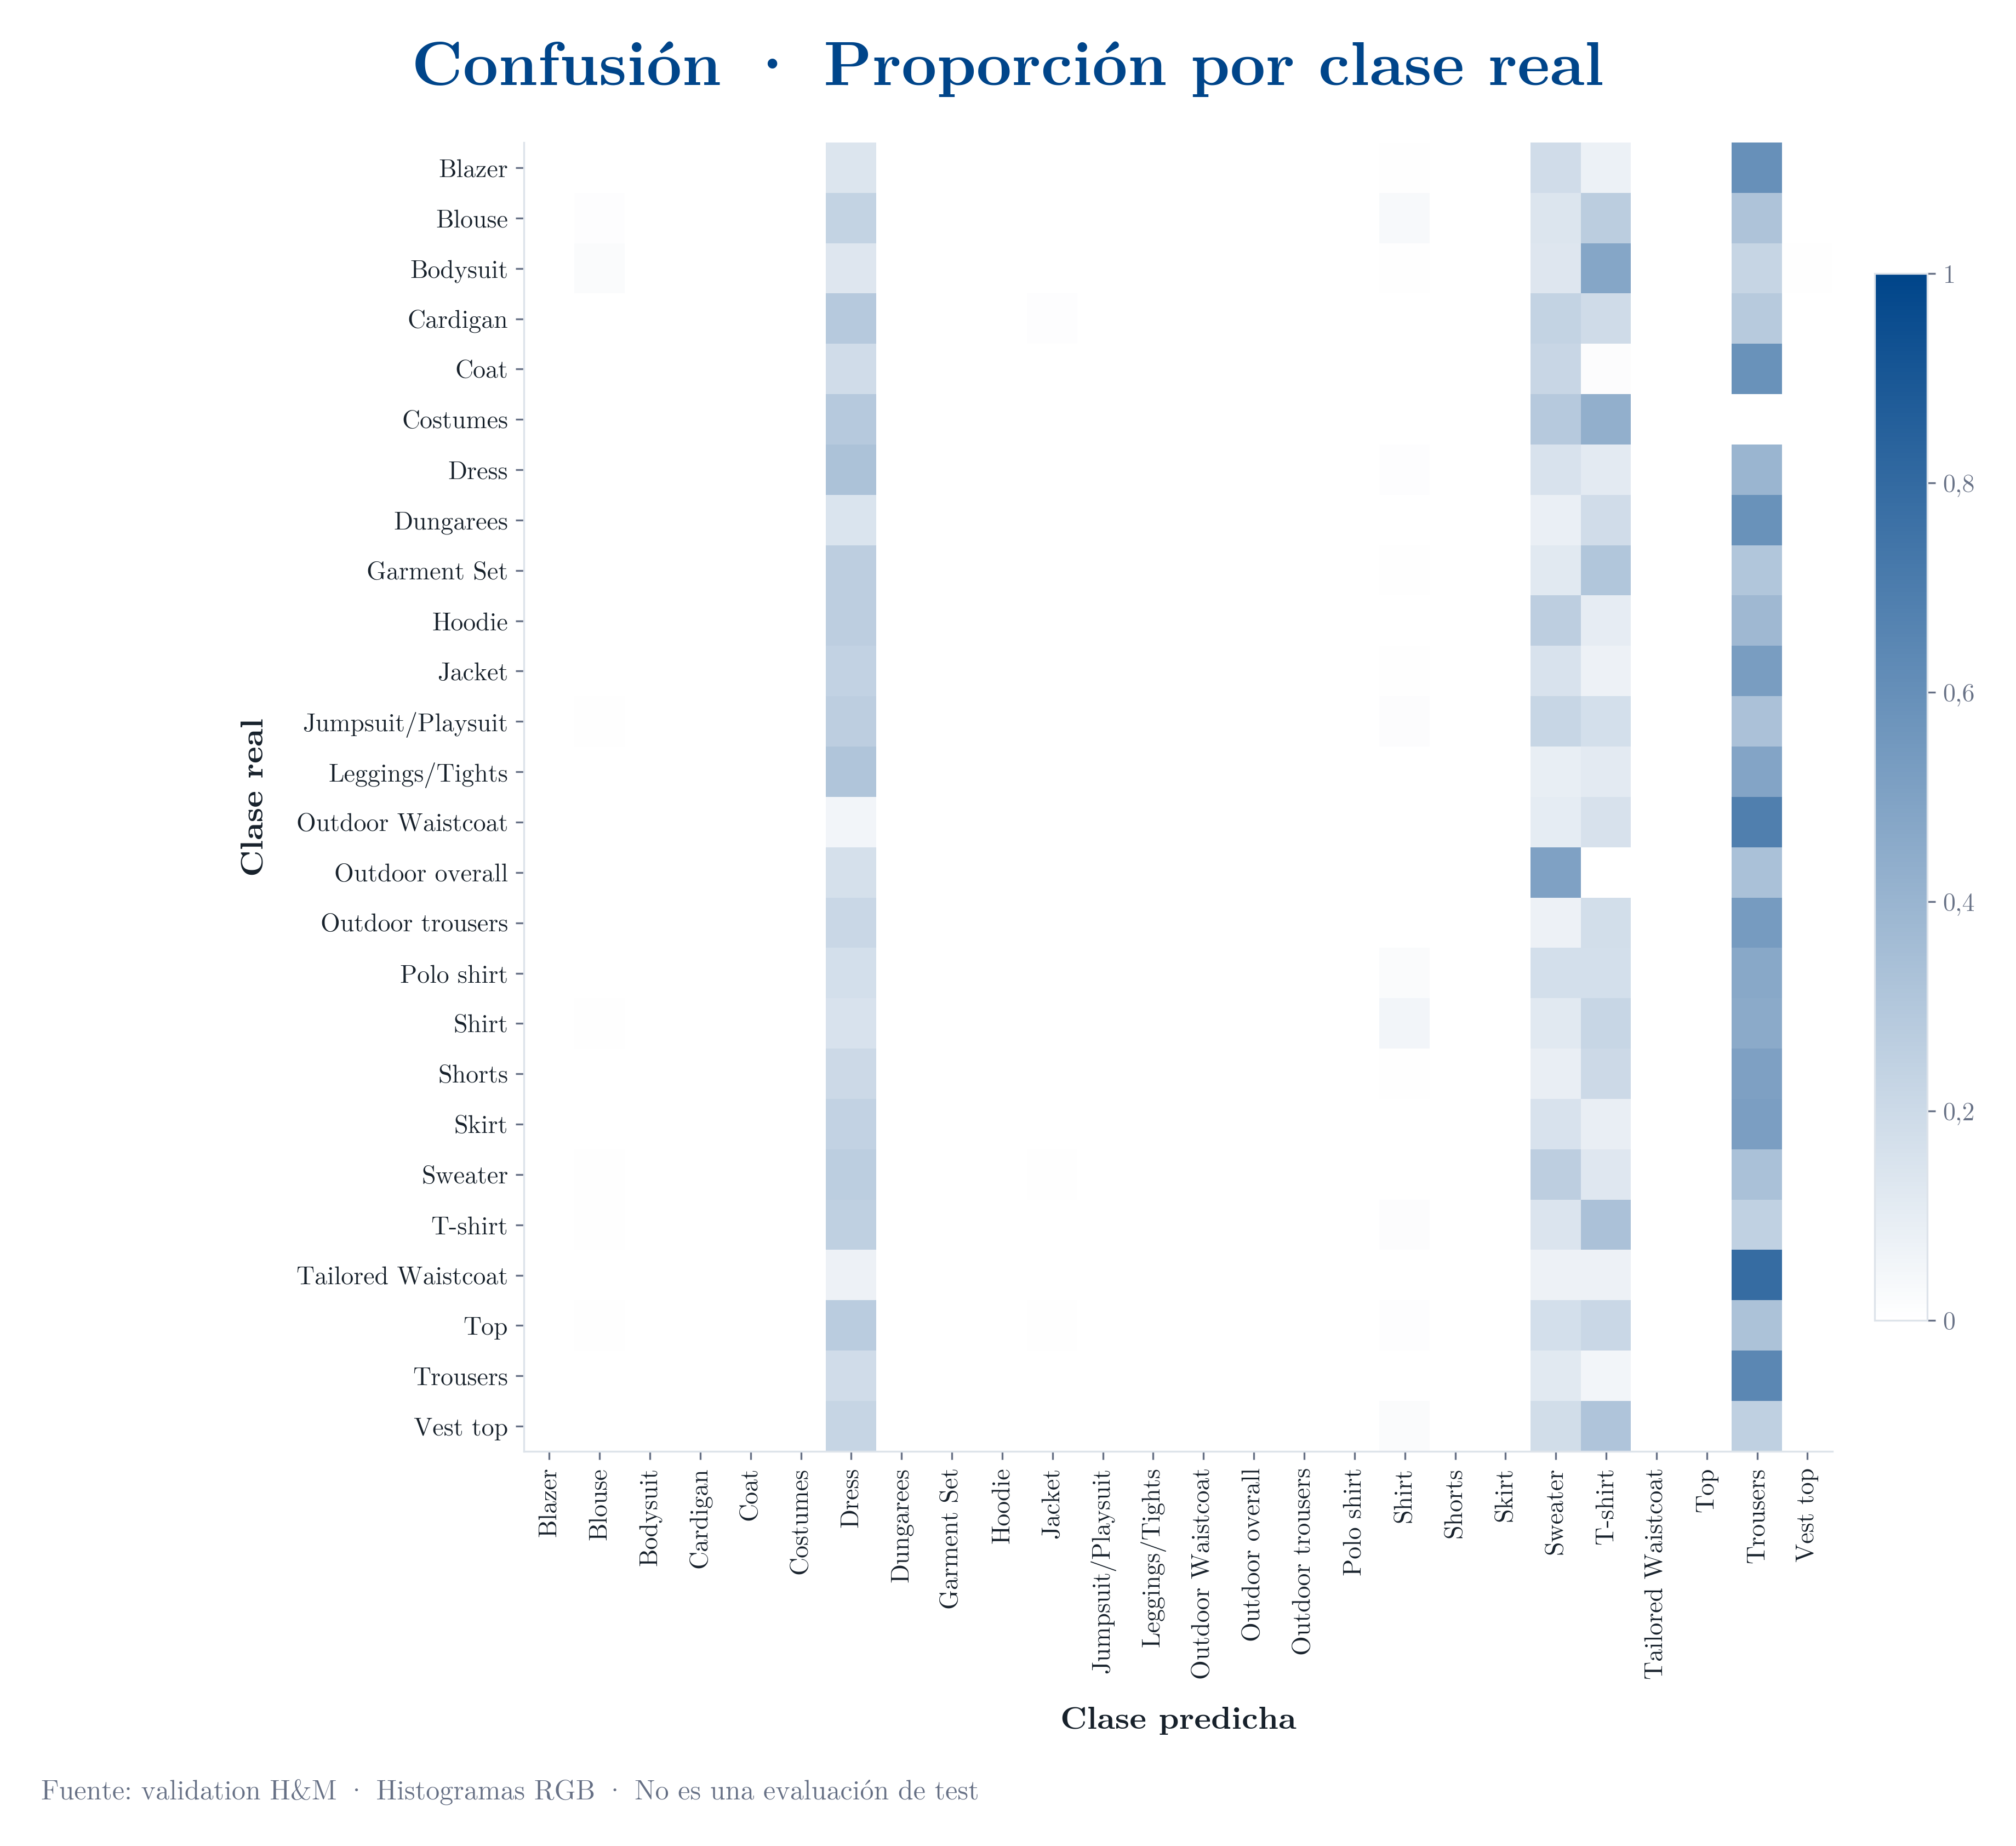

Real,Predicha,Errores,Fraccion_clase
Dress,Trousers,619,"0,397"
Sweater,Trousers,474,"0,333"
Sweater,Dress,373,"0,262"
Trousers,Dress,332,"0,187"
T-shirt,Dress,328,"0,253"
T-shirt,Trousers,321,"0,248"
Jacket,Trousers,292,"0,522"
Shorts,Trousers,273,"0,506"
Dress,Sweater,239,"0,153"
Shirt,Trousers,238,"0,453"


In [7]:
from IPython.display import Image as DisplayImage
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import confusion_matrix

cm=confusion_matrix(val_y,predictions['Logística de color'],labels=np.arange(len(names)))
row_totals=cm.sum(axis=1,keepdims=True)
cm_normalized=np.divide(cm,row_totals,out=np.zeros_like(cm,dtype=float),where=row_totals>0)
blue_scale=LinearSegmentedColormap.from_list('etsit_confusion',['#FFFFFF','#00458A'])
# Dos salidas independientes: cada matriz dispone del ancho del notebook.
for values,title,suffix,upper in [
    (cm,'Confusión · Número de imágenes','counts',None),
    (cm_normalized,'Confusión · Proporción por clase real','proportions',1),
]:
    fig,ax=plt.subplots(figsize=(12,11))
    image=ax.imshow(values,cmap=blue_scale,vmin=0,vmax=upper)
    ax.set_xticks(range(len(names)),names,rotation=90,ha='center',fontsize=11,color='#17212B')
    ax.set_yticks(range(len(names)),names,fontsize=11,color='#17212B')
    ax.set_xlabel('Clase predicha',fontsize=14)
    ax.set_ylabel('Clase real',fontsize=14)
    ax.grid(False)
    fig.suptitle(title,color='#00458A')
    bar=fig.colorbar(image,ax=ax,shrink=.8,pad=.025)
    bar.ax.tick_params(labelsize=11)
    name=f'03_colour_confusion_{suffix}'
    save_figure(fig,ROOT,name,'Fuente: validation H&M · Histogramas RGB · No es una evaluación de test')
    display(DisplayImage(filename=str(ROOT/f'results/figures/data/{name}.png'),width=950))
    plt.close(fig)
pairs=pd.DataFrame([{'Real':names[i],'Predicha':names[j],'Errores':int(cm[i,j]),'Fraccion_clase':float(cm_normalized[i,j])} for i in range(len(names)) for j in range(len(names)) if i!=j]).sort_values('Errores',ascending=False)
display(styled(pairs.head(12),3))

## 8. Qué sabemos y qué falta

La muestra visual de hasta ocho grupos de train por tipo, la composición comercial y los descriptores ayudan a estudiar diferencias entre prendas. Las anotaciones humanas pendientes no son una revisión terminada. Los dos baselines se miden en validation con intervalos que remuestrean productos completos.

La distribución desigual de clases forma parte del problema: por eso leemos macro-F1, accuracy y resultados por clase juntos. Los pesos o el balance del sampler son hipótesis de entrenamiento, no excusas para eliminar fotos válidas.

El siguiente notebook mide tiempo y memoria de una época piloto antes de decidir si el coste exige una muestra de train. Si cabe entrenar con toda la cohorte, se conserva completa. El test predictivo permanece cerrado.